# E-Commerce Sales Performance & Profitability — Analysis Notebook

Notebook ini adalah Tahap 2 dari proyek analisis dataset **Online Retail II** (UCI Machine Learning Repository):
transaksi sebuah perusahaan retail online giftware berbasis di Inggris, periode **1 Desember 2009 sampai 9 Desember 2011**.

**Pertanyaan bisnis**
1. Berapa total revenue, jumlah order, dan customer, dan bagaimana trend bulanannya?
2. Produk dan negara mana yang menyumbang revenue terbesar?
3. Seberapa besar nilai satu order (average order value dan basket size), dan seberapa terkonsentrasi revenue pada order besar?
4. Kapan pola transaksi paling ramai: bulan, hari, dan jam apa?
5. Berapa bagian customer yang kembali membeli (repeat purchase)?

**Definisi yang dipakai di seluruh notebook (sama dengan Tahap 1)**
- Revenue = `Quantity x Price` (GBP), hanya transaksi valid non-batal hasil cleaning Tahap 1.
- Order = satu nomor Invoice unik non-batal.
- Ranking produk hanya memakai StockCode berawalan digit; kode berawalan huruf adalah ongkir, penyesuaian manual, atau voucher, bukan merchandise.
- Repeat customer = customer teridentifikasi dengan 2 order atau lebih.
- Dataset tidak punya kolom cost, jadi profit margin tidak dihitung; sisi profitability diukur dari kualitas revenue (average order value, basket size, konsentrasi order besar, repeat purchase).

Catatan karakter bisnis: menurut UCI, banyak customer perusahaan ini adalah wholesaler, sehingga average order value dan basket size jauh lebih besar daripada e-commerce consumer biasa.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

KANDIDAT = [
    Path("data/online_retail_ii_clean.csv"),
    Path("../ecommerce-sales-profitability/data/online_retail_ii_clean.csv"),
    Path.home() / "workspace/ecommerce-sales-profitability/data/online_retail_ii_clean.csv",
]
path_data = next(p for p in KANDIDAT if p.exists())
df = pd.read_csv(path_data, dtype={"stock_code": str, "invoice": str})
df["invoice_date"] = pd.to_datetime(df["invoice_date"])
df["revenue_gbp"] = df["quantity"] * df["price_gbp"]  # definisi Tahap 1

print(f"File data : {path_data}")
print(f"Baris     : {len(df):,}")
print(f"Periode   : {df['invoice_date'].min()} sampai {df['invoice_date'].max()}")
df.head()

File data : ../ecommerce-sales-profitability/data/online_retail_ii_clean.csv
Baris     : 1,007,913
Periode   : 2009-12-01 07:45:00 sampai 2011-12-09 12:50:00


,invoice,stock_code,description,quantity,invoice_date,price_gbp,customer_id,country,revenue_gbp
0,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0
1,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.0,United Kingdom,59.5
2,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom,39.6


## 1. KPI Utama

Angka di bawah harus sama persis dengan `findings.json` Tahap 1 yang sudah diverifikasi dua cara
(pandas dan SQL lewat SQLite): revenue £20.476.260,43; 40.077 order; 5.878 customer teridentifikasi;
average order value £510,92.

In [2]:
orders = df.groupby("invoice").agg(
    order_revenue=("revenue_gbp", "sum"),
    order_items=("quantity", "sum"),
    customer_id=("customer_id", "first"),
).reset_index()

total_revenue = df["revenue_gbp"].sum()
total_orders = df["invoice"].nunique()
total_customers = df["customer_id"].nunique()
aov = total_revenue / total_orders

kpi = pd.Series({
    "Total revenue (GBP)": round(total_revenue, 2),
    "Total order": total_orders,
    "Total unit terjual": int(df["quantity"].sum()),
    "Customer teridentifikasi": total_customers,
    "Average order value (GBP)": round(aov, 2),
    "Median nilai order (GBP)": round(orders["order_revenue"].median(), 2),
    "Basket size rata-rata (unit per order)": round(orders["order_items"].mean(), 2),
    "Basket size median (unit per order)": orders["order_items"].median(),
    "Negara": df["country"].nunique(),
})
kpi

Total revenue (GBP)                       20476260.43
Total order                                  40077.00
Total unit terjual                        11205148.00
Customer teridentifikasi                      5878.00
Average order value (GBP)                      510.92
Median nilai order (GBP)                       302.22
Basket size rata-rata (unit per order)         279.59
Basket size median (unit per order)            146.00
Negara                                          43.00
dtype: float64

Nilai order yang besar dan basket size ratusan unit menegaskan karakter wholesale dataset ini.
Median nilai order (£302,22) jauh di bawah rata-ratanya (£510,92), tanda distribusi nilai order miring ke kanan:
sebagian kecil order bernilai sangat besar menarik rata-rata ke atas.

## 2. Trend Bulanan

November adalah puncak di kedua tahun. Desember 2011 tidak bisa dibandingkan sebagai bulan penuh
karena data berakhir 9 Desember 2011.

In [3]:
monthly = df.set_index("invoice_date").resample("ME").agg(
    revenue=("revenue_gbp", "sum"), orders=("invoice", "nunique"), units=("quantity", "sum")
).reset_index()
monthly["year_month"] = monthly["invoice_date"].dt.strftime("%Y-%m")
monthly["aov"] = (monthly["revenue"] / monthly["orders"]).round(2)
monthly[["year_month", "revenue", "orders", "units", "aov"]]

,year_month,revenue,orders,units,aov
0,2009-12,822483.95,1682,425461,488.99
1,2010-01,651155.11,1105,390672,589.28
2,2010-02,551504.72,1201,381879,459.20
3,2010-03,830915.26,1681,526026,494.30
4,2010-04,678875.25,1462,366705,464.35
5,2010-05,657705.50,1500,395868,438.47
6,2010-06,749537.31,1645,406820,455.65
7,2010-07,648810.27,1529,337895,424.34
8,2010-08,695251.91,1425,472380,487.90
9,2010-09,921696.99,1839,583864,501.19


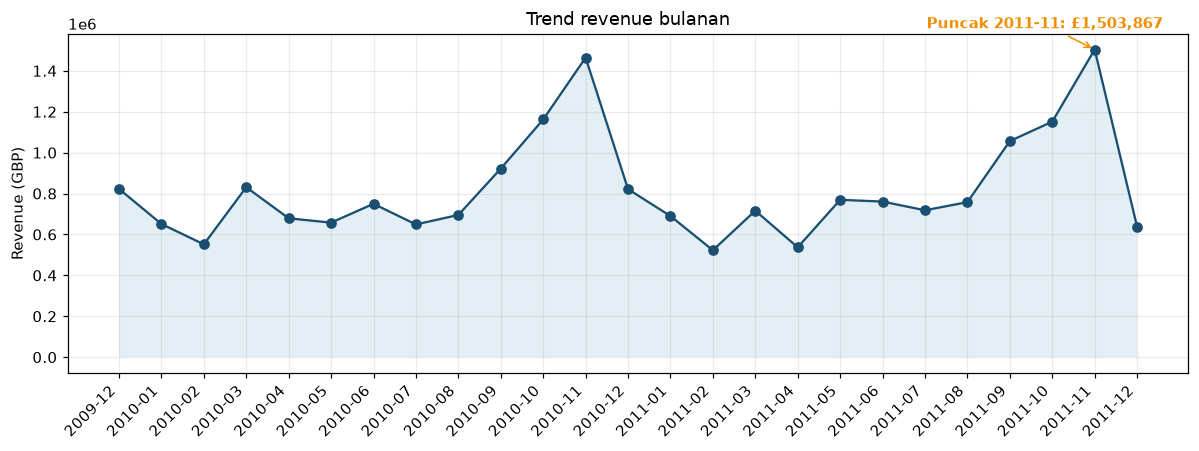

Bulan terbaik: 2011-11 dengan revenue £1,503,866.78


In [4]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(monthly["year_month"], monthly["revenue"], marker="o", color="#1B4F72")
ax.fill_between(range(len(monthly)), monthly["revenue"], alpha=0.12)
best = monthly.loc[monthly["revenue"].idxmax()]
ax.annotate(f"Puncak {best['year_month']}: £{best['revenue']:,.0f}",
            xy=(list(monthly['year_month']).index(best['year_month']), best['revenue']),
            xytext=(-110, 14), textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color="#F18F01"), color="#F18F01", fontweight="bold")
ax.set_title("Trend revenue bulanan")
ax.set_ylabel("Revenue (GBP)")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout(); plt.show()
print(f"Bulan terbaik: {best['year_month']} dengan revenue £{best['revenue']:,.2f}")

## 3. Pola Musiman: Bulan x Tahun

Heatmap ini memperlihatkan konsentrasi revenue di kuartal terakhir, terutama November,
konsisten di 2010 dan 2011. Kolom 2009 hanya berisi Desember, dan 2011 berakhir 9 Desember.

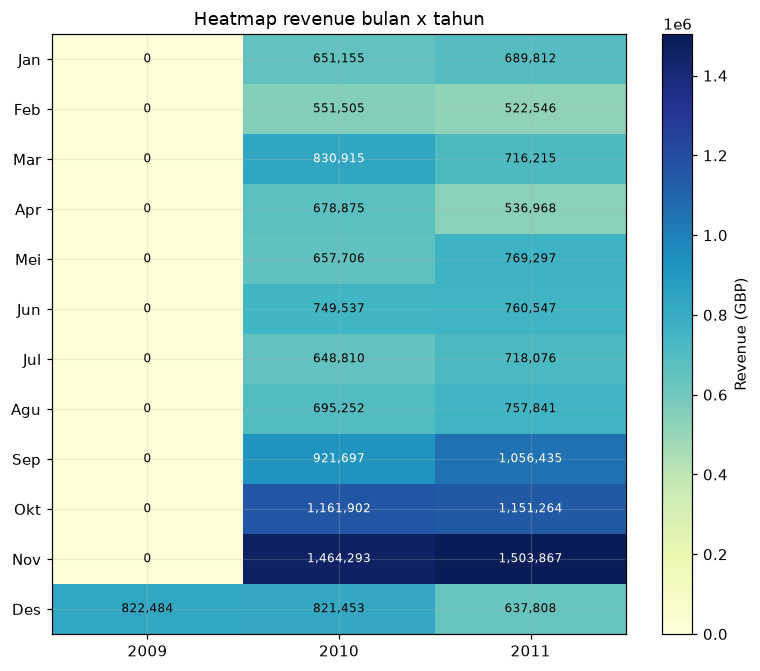

year,2009,2010,2011
month,,,
1,0.00,651155.11,689811.61
2,0.00,551504.72,522545.56
3,0.00,830915.26,716215.26
4,0.00,678875.25,536968.49
5,0.00,657705.50,769296.61
6,0.00,749537.31,760547.01
7,0.00,648810.27,718076.12
8,0.00,695251.91,757841.38
9,0.00,921696.99,1056435.19


In [5]:
seas = df.copy()
seas["year"] = seas["invoice_date"].dt.year
seas["month"] = seas["invoice_date"].dt.month
pivot = seas.groupby(["month", "year"])["revenue_gbp"].sum().unstack(fill_value=0)
pivot = pivot.reindex(index=range(1, 13), columns=[2009, 2010, 2011]).fillna(0)

fig, ax = plt.subplots(figsize=(7.2, 6.2))
im = ax.imshow(pivot.values, cmap="YlGnBu", aspect="auto")
ax.set_xticks(range(3), ["2009", "2010", "2011"])
ax.set_yticks(range(12), ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"])
for i in range(12):
    for j in range(3):
        v = pivot.values[i, j]
        ax.text(j, i, f"{v:,.0f}", ha="center", va="center", fontsize=8,
                color="white" if v > pivot.values.max() * 0.55 else "black")
ax.set_title("Heatmap revenue bulan x tahun")
fig.colorbar(im, ax=ax, label="Revenue (GBP)")
plt.tight_layout(); plt.show()
pivot.round(2)

## 4. Pola Jam dan Hari

Aktivitas mengikuti jam kerja: hampir semua order terjadi pukul 08.00 sampai 17.00 dengan puncak pukul 12.00.
Thursday adalah hari tersibuk, Saturday hampir tidak ada transaksi, sementara Sunday justru ramai.

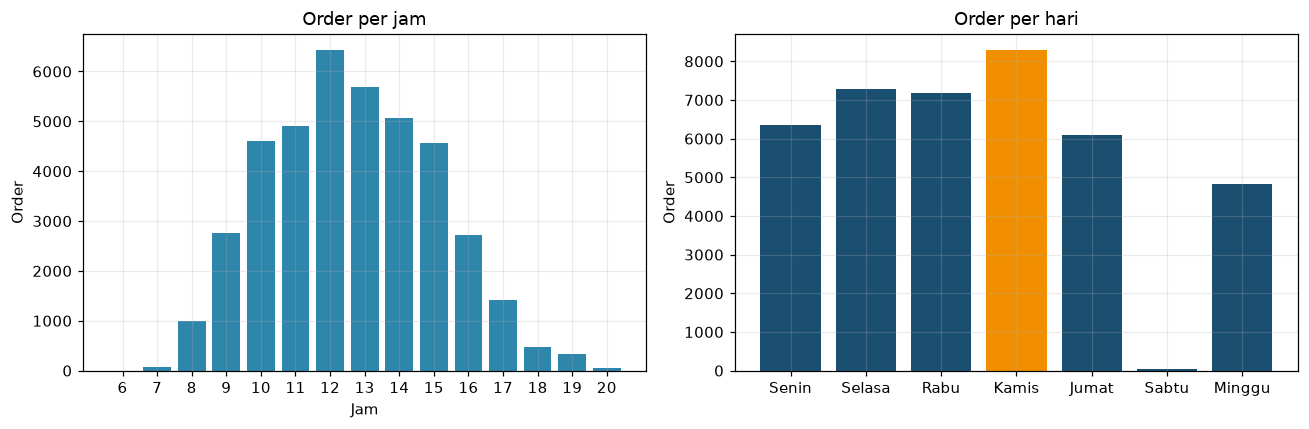

Jam puncak: pukul 12.00 dengan 6,427 order
Hari tersibuk: Thursday dengan 8,288 order


In [6]:
df["hour"] = df["invoice_date"].dt.hour
df["weekday"] = df["invoice_date"].dt.day_name()
hourly = df.groupby("hour").agg(revenue=("revenue_gbp", "sum"), orders=("invoice", "nunique"))
order_days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday = df.groupby("weekday").agg(revenue=("revenue_gbp", "sum"), orders=("invoice", "nunique")).reindex(order_days)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(hourly.index.astype(str), hourly["orders"], color="#2E86AB")
axes[0].set_title("Order per jam"); axes[0].set_xlabel("Jam"); axes[0].set_ylabel("Order")
axes[1].bar(["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"], weekday["orders"],
            color=["#F18F01" if d == "Thursday" else "#1B4F72" for d in order_days])
axes[1].set_title("Order per hari"); axes[1].set_ylabel("Order")
plt.tight_layout(); plt.show()

print(f"Jam puncak: pukul {int(hourly['orders'].idxmax())}.00 dengan {int(hourly['orders'].max()):,} order")
print(f"Hari tersibuk: {weekday['orders'].idxmax()} dengan {int(weekday['orders'].max()):,} order")

## 5. Top Produk

Ranking hanya memakai StockCode berawalan digit. Satu catatan penting: produk nomor 4,
PAPER CRAFT , LITTLE BIRDIE, seluruh revenuenya berasal dari satu order terbesar di dataset
(invoice 581483), bukan dari penjualan berulang.

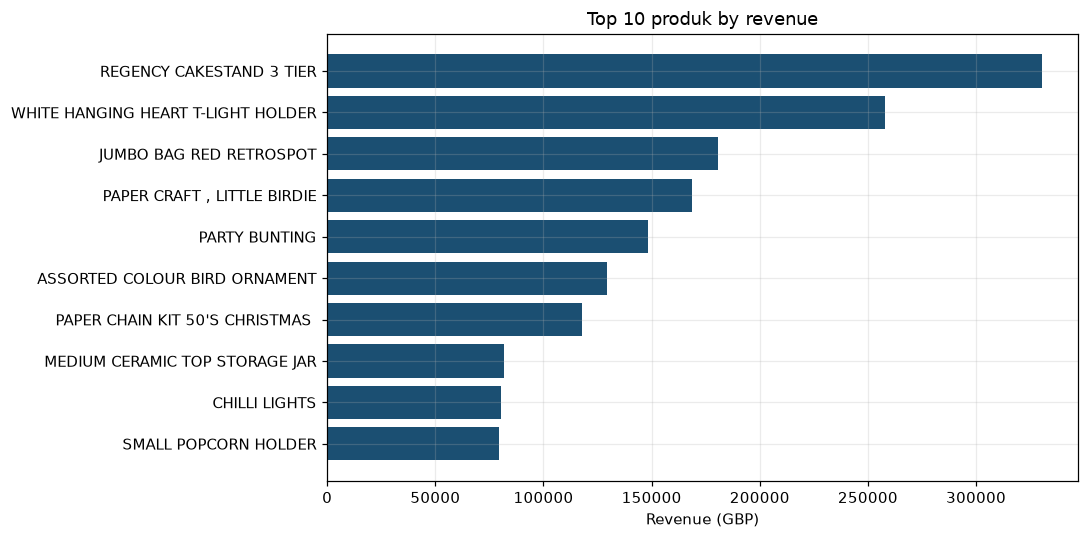

Share top 10 produk terhadap total revenue: 7.69%


,description,revenue,units,orders
stock_code,,,,
22423,REGENCY CAKESTAND 3 TIER,330590.32,26478,3918
85123A,WHITE HANGING HEART T-LIGHT HOLDER,257724.71,94203,5365
85099B,JUMBO BAG RED RETROSPOT,180569.34,96757,3989
23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
47566,PARTY BUNTING,148318.28,28200,2674
84879,ASSORTED COLOUR BIRD ORNAMENT,129324.49,80082,2807
22086,PAPER CHAIN KIT 50'S CHRISTMAS,117760.29,35084,2018
23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247
79321,CHILLI LIGHTS,80540.88,15841,1135


In [7]:
prod = df[df["stock_code"].str.match(r"^\d", na=False)].copy()
desc_map = prod.groupby("stock_code")["description"].agg(lambda s: s.mode().iat[0] if len(s.mode()) else "")
top10 = prod.groupby("stock_code").agg(
    revenue=("revenue_gbp", "sum"), units=("quantity", "sum"), orders=("invoice", "nunique")
).nlargest(10, "revenue")
top10["description"] = [desc_map.get(i, "") for i in top10.index]
top10 = top10[["description", "revenue", "units", "orders"]].round(2)

fig, ax = plt.subplots(figsize=(10, 5))
plot10 = top10.iloc[::-1]
ax.barh([str(d)[:42] for d in plot10["description"]], plot10["revenue"], color="#1B4F72")
ax.set_title("Top 10 produk by revenue")
ax.set_xlabel("Revenue (GBP)")
plt.tight_layout(); plt.show()
print(f"Share top 10 produk terhadap total revenue: {top10['revenue'].sum() / total_revenue * 100:.2f}%")
top10

Top 10 produk hanya menyumbang 7,69% revenue: revenue tersebar di banyak produk
dan tidak bergantung pada sedikit produk unggulan.

## 6. Negara: Dominasi United Kingdom

United Kingdom menyumbang 85,03% revenue. Sisanya tersebar di 42 negara, dengan EIRE terbesar
tetapi hanya berasal dari 5 customer, jadi konsentrasi customer di pasar terbesar kedua ini tinggi.

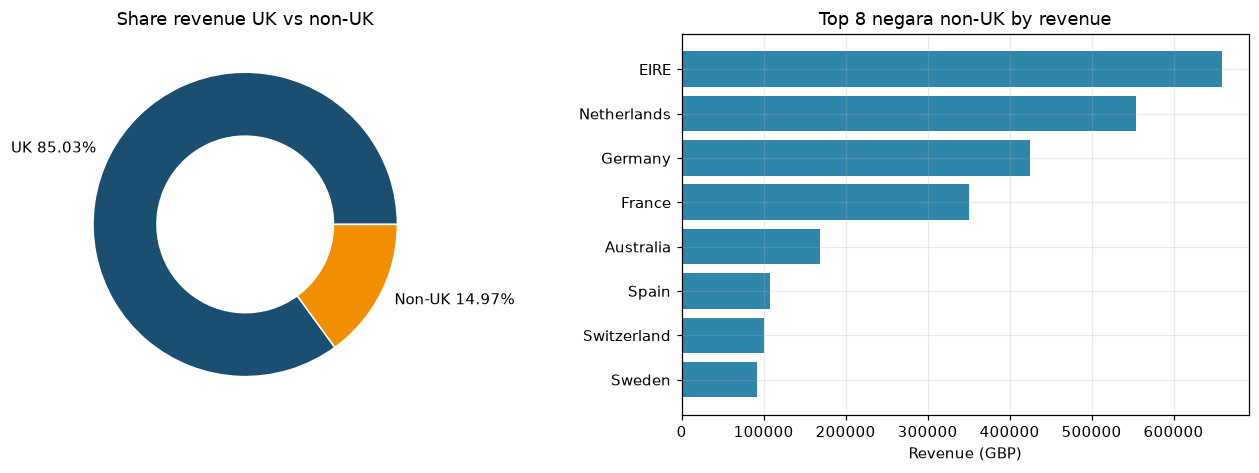

,revenue,orders,customers,units
country,,,,
United Kingdom,17410196.10,36535,5350,9187753
EIRE,658767.31,626,5,336329
Netherlands,554038.09,228,22,383879
Germany,425019.71,789,107,225154
France,350456.09,622,95,271901
Australia,169283.46,95,15,103759
Spain,108332.49,154,41,50307
Switzerland,100685.59,93,22,52762
Sweden,91869.82,105,19,88633


In [8]:
country = df.groupby("country").agg(
    revenue=("revenue_gbp", "sum"), orders=("invoice", "nunique"),
    customers=("customer_id", "nunique"), units=("quantity", "sum"),
).sort_values("revenue", ascending=False)
uk_share = country.loc["United Kingdom", "revenue"] / total_revenue * 100
nonuk = country[country.index != "United Kingdom"].head(8)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].pie([country.loc["United Kingdom", "revenue"], total_revenue - country.loc["United Kingdom", "revenue"]],
            labels=[f"UK {uk_share:.2f}%", f"Non-UK {100 - uk_share:.2f}%"],
            colors=["#1B4F72", "#F18F01"], wedgeprops=dict(width=0.42, edgecolor="white"))
axes[0].set_title("Share revenue UK vs non-UK")
axes[1].barh(nonuk.index[::-1], nonuk["revenue"].iloc[::-1], color="#2E86AB")
axes[1].set_title("Top 8 negara non-UK by revenue"); axes[1].set_xlabel("Revenue (GBP)")
plt.tight_layout(); plt.show()
country.head(10).round(2)

## 7. Distribusi Nilai Order dan Average Order Value per Bulan

Distribusi nilai order dipotong di persentil 99 agar terbaca; ekor kanannya yang panjang
adalah order wholesale besar. Average order value Desember 2011 yang tinggi ikut terangkat
oleh order terbesar di dataset yang terjadi pada 9 Desember 2011.

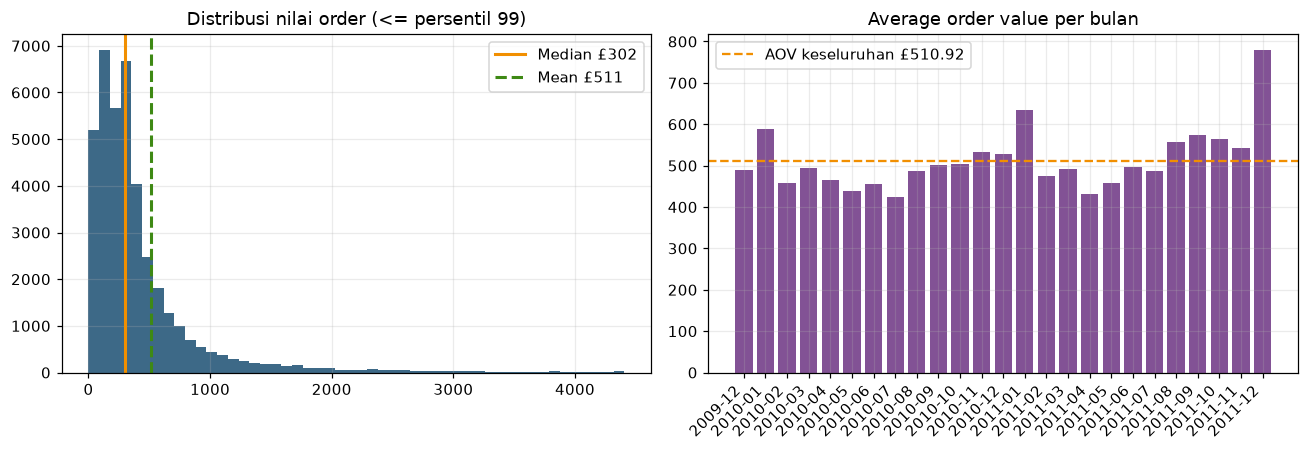

Persentil 99 nilai order: £4,408.59 | Order maksimum: £168,469.60


In [9]:
vals = orders["order_revenue"]
clip = vals.quantile(0.99)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(vals[vals <= clip], bins=50, color="#1B4F72", alpha=0.85)
axes[0].axvline(vals.median(), color="#F18F01", linewidth=2, label=f"Median £{vals.median():,.0f}")
axes[0].axvline(vals.mean(), color="#3E8914", linestyle="--", linewidth=2, label=f"Mean £{vals.mean():,.0f}")
axes[0].set_title("Distribusi nilai order (<= persentil 99)"); axes[0].legend()
axes[1].bar(monthly["year_month"], monthly["aov"], color="#6C3483", alpha=0.85)
axes[1].axhline(aov, color="#F18F01", linestyle="--", label=f"AOV keseluruhan £{aov:,.2f}")
axes[1].set_title("Average order value per bulan"); axes[1].legend()
plt.setp(axes[1].get_xticklabels(), rotation=45, ha="right")
plt.tight_layout(); plt.show()
print(f"Persentil 99 nilai order: £{clip:,.2f} | Order maksimum: £{vals.max():,.2f}")

## 8. Konsentrasi Order Besar

Hanya 93 order yang bernilai di atas £10.000, tetapi kelompok kecil itu menyumbang 8,87% revenue.
Revenue cukup sensitif terhadap sedikit order wholesale besar, dan kehilangan beberapa customer
pembeli besar akan terasa langsung pada total revenue.

Order > £10.000 : 93 order (0.23% dari semua order)
Revenue mereka  : £1,817,057.46 (8.87% dari total revenue)
Order <= £10.000: 39,984 order, revenue £18,659,202.97
Order terbesar  : invoice 581483 senilai £168,469.60


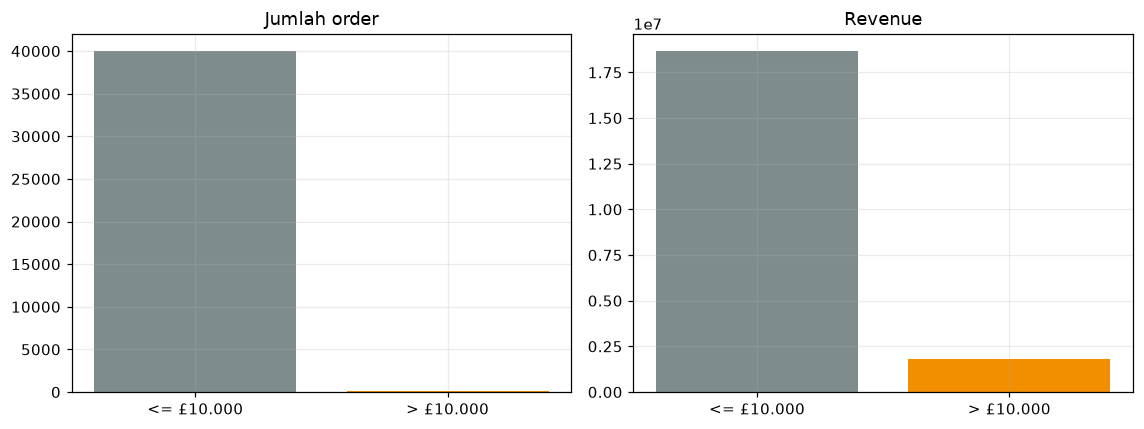

In [10]:
big = orders[orders["order_revenue"] > 10000]
small = orders[orders["order_revenue"] <= 10000]
print(f"Order > £10.000 : {len(big):,} order ({len(big) / len(orders) * 100:.2f}% dari semua order)")
print(f"Revenue mereka  : £{big['order_revenue'].sum():,.2f} ({big['order_revenue'].sum() / total_revenue * 100:.2f}% dari total revenue)")
print(f"Order <= £10.000: {len(small):,} order, revenue £{small['order_revenue'].sum():,.2f}")
print(f"Order terbesar  : invoice {orders.loc[orders['order_revenue'].idxmax(), 'invoice']} "
      f"senilai £{orders['order_revenue'].max():,.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
axes[0].bar(["<= £10.000", "> £10.000"], [len(small), len(big)], color=["#7F8C8D", "#F18F01"])
axes[0].set_title("Jumlah order")
axes[1].bar(["<= £10.000", "> £10.000"], [small["order_revenue"].sum(), big["order_revenue"].sum()],
            color=["#7F8C8D", "#F18F01"])
axes[1].set_title("Revenue")
plt.tight_layout(); plt.show()

## 9. Repeat Customer

72,39% customer teridentifikasi membeli 2 kali atau lebih, dengan median 3 order per customer.
Di sisi lain, 3.108 order (revenue £3.101.456,18 atau 15,15%) tidak memiliki Customer ID,
sehingga analisis customer hanya mencakup sekitar 85% revenue. Ringkasan per customer dari bagian ini
tersimpan sebagai file data Tahap 2: `data/customer_repeat_summary.csv` (dibuat oleh `scripts/build_charts.py`).

Customer teridentifikasi : 5,878
Repeat (>= 2 order)      : 4,255 (72.39%)
One-time (1 order)       : 1,623 (27.61%)
Median order per customer: 3
Revenue dari repeat customer: £16,814,531.69


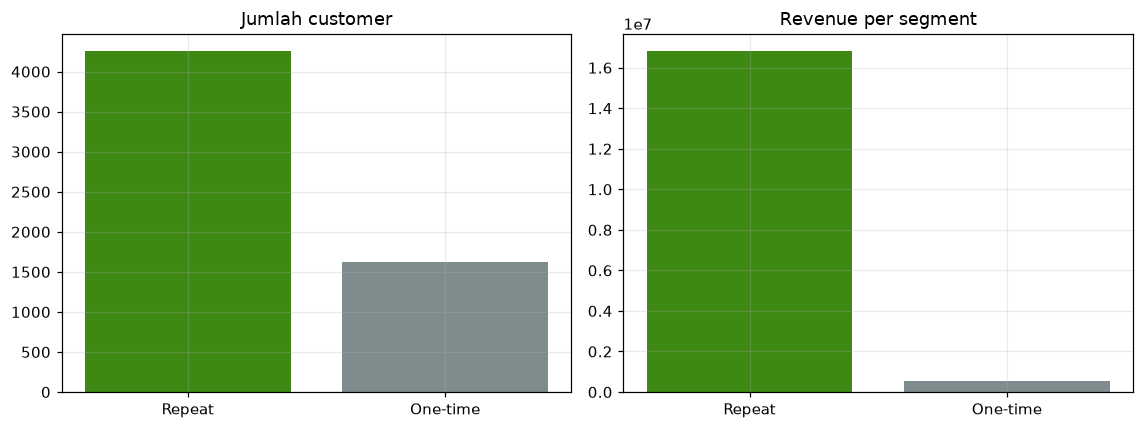

In [11]:
cust_orders = orders.dropna(subset=["customer_id"]).groupby("customer_id").agg(
    total_orders=("invoice", "nunique"), total_revenue=("order_revenue", "sum"),
)
repeat = cust_orders[cust_orders["total_orders"] >= 2]
one_time = cust_orders[cust_orders["total_orders"] == 1]
print(f"Customer teridentifikasi : {len(cust_orders):,}")
print(f"Repeat (>= 2 order)      : {len(repeat):,} ({len(repeat) / len(cust_orders) * 100:.2f}%)")
print(f"One-time (1 order)       : {len(one_time):,} ({len(one_time) / len(cust_orders) * 100:.2f}%)")
print(f"Median order per customer: {cust_orders['total_orders'].median():.0f}")
print(f"Revenue dari repeat customer: £{repeat['total_revenue'].sum():,.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
axes[0].bar(["Repeat", "One-time"], [len(repeat), len(one_time)], color=["#3E8914", "#7F8C8D"])
axes[0].set_title("Jumlah customer")
axes[1].bar(["Repeat", "One-time"], [repeat["total_revenue"].sum(), one_time["total_revenue"].sum()],
            color=["#3E8914", "#7F8C8D"])
axes[1].set_title("Revenue per segment")
plt.tight_layout(); plt.show()

## Kesimpulan

1. **Revenue £20.476.260,43 dari 40.077 order**, dengan average order value £510,92 yang khas wholesale.
2. **November adalah puncak musiman di kedua tahun** (terbaik: November 2011, £1.503.866,78), konsisten dengan lonjakan pre-Christmas untuk giftware.
3. **United Kingdom mendominasi 85,03% revenue**; pasar internasional terbesar berikutnya (EIRE) hanya ditopang 5 customer.
4. **Revenue tidak terkonsentrasi di produk** (top 10 hanya 7,69%), tetapi **cukup terkonsentrasi di order besar**: 93 order di atas £10.000 menyumbang 8,87%.
5. **Repeat purchase kuat (72,39%)**, tetapi 15,15% revenue tidak teratribusi ke customer mana pun karena Customer ID kosong.
6. **Pola waktu mengikuti jam dan hari kerja** (puncak pukul 12.00, Kamis tersibuk, Sabtu hampir kosong), konsisten dengan basis customer wholesaler.

Seluruh chart versi file dari analisis ini ada di folder `charts/` dan dibuat oleh `scripts/build_charts.py`.
Langkah berikutnya (Tahap 3): kit Power BI dan paket PBIP, deck presentasi, dan modul.